In [21]:
import sys
from pathlib import Path

PROJECT_ROOT = Path(
    "/media/ehsan/MyFiles2/FraUAS/HIS Project/Code/ptbxl-patient-conditioned-ecg-forecasting"
)

sys.path.insert(0, str(PROJECT_ROOT / "src"))

from config import load_config

cfg = load_config(PROJECT_ROOT / "configs/config.yaml")

cfg["data"]["root"] = (
    "/media/ehsan/MyFiles2/FraUAS/HIS Project/PTB-XL"
)

print(cfg["data"])

{'root': '/media/ehsan/MyFiles2/FraUAS/HIS Project/PTB-XL', 'sampling_rate': 100, 'history': 700, 'horizon': 300, 'synthetic': False, 'start': 0, 'layout': 'time_first'}


In [22]:
from config import load_config

cfg = load_config(PROJECT_ROOT / "configs/config.yaml")

cfg["data"]["root"] = (
    "/media/ehsan/MyFiles2/FraUAS/HIS Project/PTB-XL"
)

print(cfg["data"])

{'root': '/media/ehsan/MyFiles2/FraUAS/HIS Project/PTB-XL', 'sampling_rate': 100, 'history': 700, 'horizon': 300, 'synthetic': False, 'start': 0, 'layout': 'time_first'}


In [23]:
from data import prepare

cache, manifest = prepare(cfg)

print("Cache:", cache)
print(manifest["splits"])

Cache: data/study_v3/ee7d4f585e459326
{'train': {'records': 339, 'patients': 300, 'windows': 339}, 'val': {'records': 81, 'patients': 75, 'windows': 81}}


In [8]:
from pathlib import Path

FIG_DIR = Path("figures")

(FIG_DIR / "patchtst").mkdir(parents=True, exist_ok=True)
(FIG_DIR / "tft").mkdir(parents=True, exist_ok=True)
(FIG_DIR / "comparison").mkdir(parents=True, exist_ok=True)
(FIG_DIR / "leads").mkdir(parents=True, exist_ok=True)


In [4]:
# Figure 1 - PatchTST P0 Training Progress

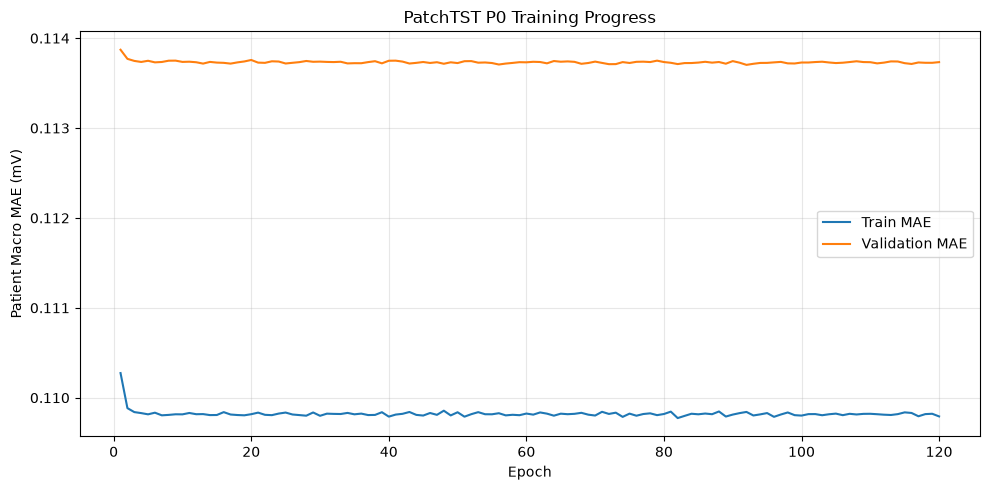

In [51]:
import pandas as pd
import matplotlib.pyplot as plt

history = pd.read_csv(
    "results/primary_7s3s_v3/full/checkpoints/patchtst_P0_F0_full_120e/history.csv"
)

plt.figure(figsize=(10,5))

plt.plot(
    history["epoch"],
    history["train_patient_macro_mae_mV"],
    label="Train MAE",
)

plt.plot(
    history["epoch"],
    history["val_patient_macro_mae_mV"],
    label="Validation MAE",
)

plt.xlabel("Epoch")
plt.ylabel("Patient Macro MAE (mV)")
plt.title("PatchTST P0 Training Progress")
plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()

plt.savefig(
    FIG_DIR / "patchtst" / "patchtst_p0_training_progress.png",
    dpi=300,
    bbox_inches="tight"
)

caption = """
Figure 1.
Training and validation patient-macro MAE for PatchTST trained on
raw ECG waveforms (P0). The model converges during early epochs
and stabilizes close to the optimal validation performance.
"""

(
    FIG_DIR
    / "patchtst"
    / "patchtst_p0_training_progress.txt"
).write_text(caption)

plt.show()

In [56]:
# Figure 2 - PatchTST P0 Validation RMSE

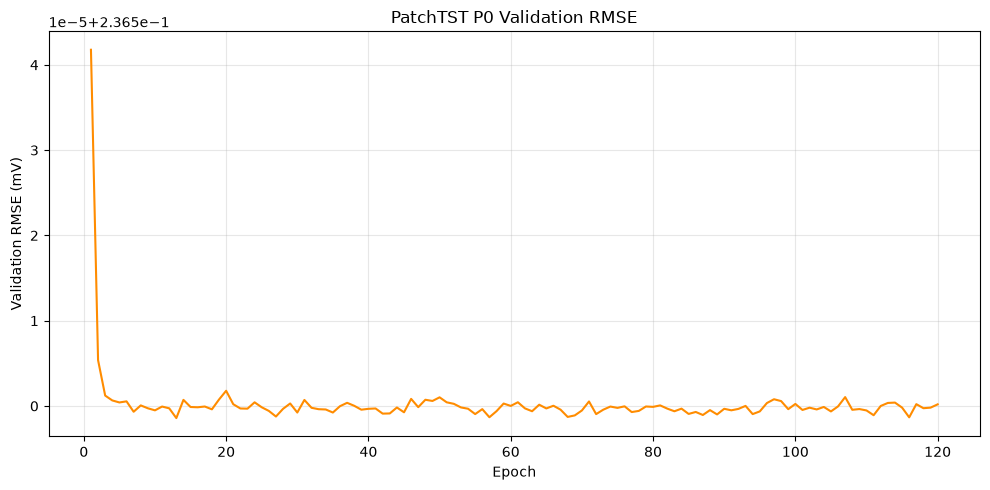

In [54]:
import pandas as pd
import matplotlib.pyplot as plt

history = pd.read_csv(
    "results/primary_7s3s_v3/full/checkpoints/patchtst_P0_F0_full_120e/history.csv"
)

plt.figure(figsize=(10,5))

plt.plot(
    history["epoch"],
    history["val_rmse_mV"],
    color="darkorange"
)

plt.xlabel("Epoch")
plt.ylabel("Validation RMSE (mV)")
plt.title("PatchTST P0 Validation RMSE")
plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    FIG_DIR / "patchtst" / "patchtst_p0_validation_rmse.png",
    dpi=300,
    bbox_inches="tight"
)

caption = """
Figure 2.
Validation RMSE obtained by PatchTST on raw ECG signals (P0)
throughout training.
"""

(
    FIG_DIR
    / "patchtst"
    / "patchtst_p0_validation_rmse.txt"
).write_text(caption)

plt.show()

In [8]:
# Figure 3 - PatchTST P0 Train vs Validation RMSE

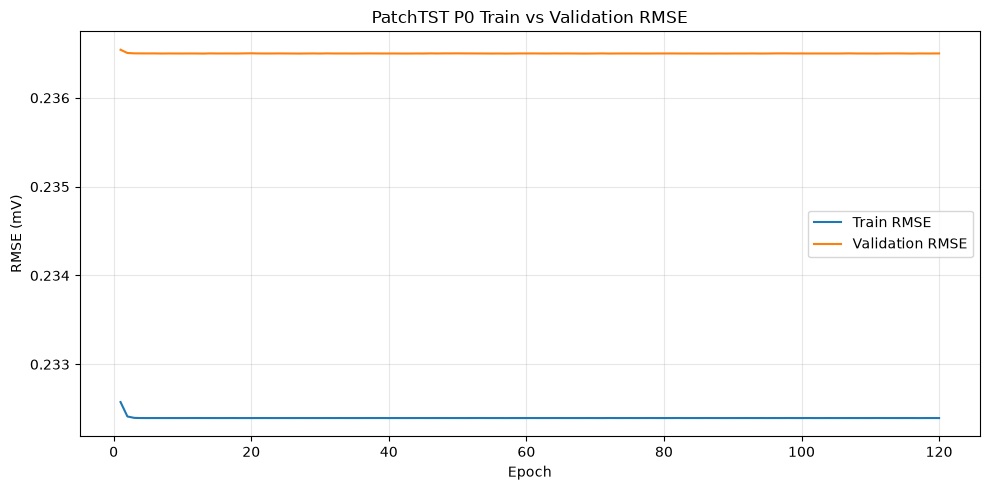

In [55]:
import pandas as pd
import matplotlib.pyplot as plt

history = pd.read_csv(
    "results/primary_7s3s_v3/full/checkpoints/patchtst_P0_F0_full_120e/history.csv"
)

plt.figure(figsize=(10,5))

plt.plot(
    history["epoch"],
    history["train_rmse_mV"],
    label="Train RMSE"
)

plt.plot(
    history["epoch"],
    history["val_rmse_mV"],
    label="Validation RMSE"
)

plt.xlabel("Epoch")
plt.ylabel("RMSE (mV)")
plt.title("PatchTST P0 Train vs Validation RMSE")

plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()

plt.savefig(
    FIG_DIR / "patchtst" / "patchtst_p0_train_vs_validation_rmse.png",
    dpi=300,
    bbox_inches="tight"
)

caption = """
Figure 3.
Training and validation RMSE curves for PatchTST trained on
raw ECG waveforms. The similarity of both curves indicates
stable generalization.
"""

(
    FIG_DIR
    / "patchtst"
    / "patchtst_p0_train_vs_validation_rmse.txt"
).write_text(caption)

plt.show()

In [10]:
best_epoch = history.loc[
    history["val_patient_macro_mae_mV"].idxmin()
]

print(best_epoch)

epoch                         92.000000
seconds                       80.161674
lr                             0.000500
train_mse_normalized           0.991165
train_mae_mV                   0.110006
train_rmse_mV                  0.232395
train_patient_macro_mae_mV     0.109842
val_mse_normalized             0.990605
val_mae_mV                     0.114212
val_rmse_mV                    0.236500
val_patient_macro_mae_mV       0.113703
Name: 91, dtype: float64


In [ ]:
# Figure 4 - PatchTST Best Checkpoint

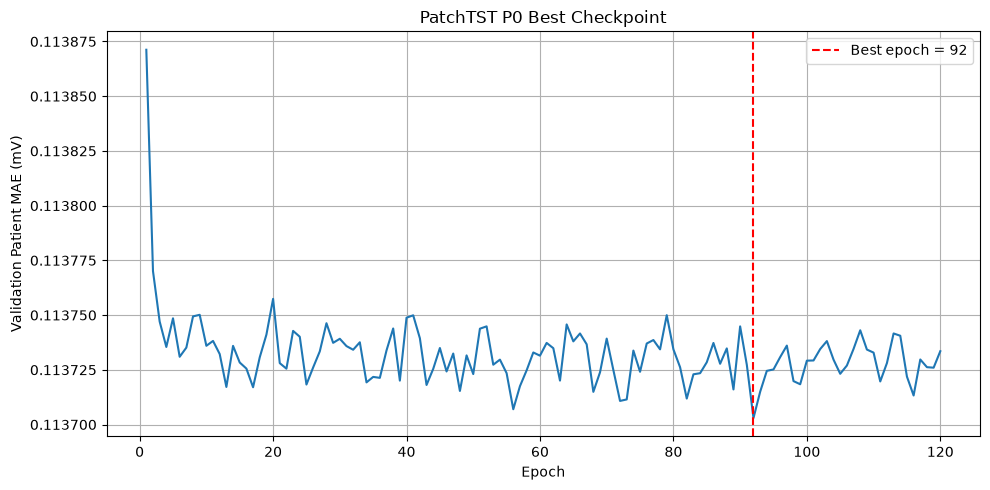

In [57]:
import pandas as pd
import matplotlib.pyplot as plt

history = pd.read_csv(
    "results/primary_7s3s_v3/full/checkpoints/patchtst_P0_F0_full_120e/history.csv"
)

best_epoch = history.loc[
    history["val_patient_macro_mae_mV"].idxmin()
]

plt.figure(figsize=(10,5))

plt.plot(
    history["epoch"],
    history["val_patient_macro_mae_mV"],
)

plt.axvline(
    best_epoch["epoch"],
    color="red",
    linestyle="--",
    label=f"Best epoch = {int(best_epoch['epoch'])}"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Patient MAE (mV)")
plt.title("PatchTST P0 Best Checkpoint")

plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    FIG_DIR / "patchtst" / "patchtst_p0_best_checkpoint.png",
    dpi=300,
    bbox_inches="tight"
)

caption = f"""
Figure 4.
Validation patient-macro MAE for PatchTST P0. The selected
checkpoint occurs at epoch {int(best_epoch['epoch'])}, where
the lowest validation error was achieved.
"""

(
    FIG_DIR
    / "patchtst"
    / "patchtst_p0_best_checkpoint.txt"
).write_text(caption)

plt.show()

In [12]:
import pandas as pd

p0 = pd.read_csv(
    "results/primary_7s3s_v3/full/checkpoints/patchtst_P0_F0_full_120e/history.csv"
)

p1 = pd.read_csv(
    "results/primary_7s3s_v3/full/checkpoints/patchtst_P1_F0_full_120e/history.csv"
)


In [13]:
# Best Validation epochs

In [14]:
best_p0 = p0.loc[p0["val_patient_macro_mae_mV"].idxmin()]
best_p1 = p1.loc[p1["val_patient_macro_mae_mV"].idxmin()]

comparison = pd.DataFrame(
    [
        {
            "Run": "PatchTST P0",
            "Epoch": int(best_p0["epoch"]),
            "Val MAE": best_p0["val_patient_macro_mae_mV"],
            "Val RMSE": best_p0["val_rmse_mV"],
            "Val MSE": best_p0["val_mse_normalized"],
        },
        {
            "Run": "PatchTST P1",
            "Epoch": int(best_p1["epoch"]),
            "Val MAE": best_p1["val_patient_macro_mae_mV"],
            "Val RMSE": best_p1["val_rmse_mV"],
            "Val MSE": best_p1["val_mse_normalized"],
        }
    ]
)

comparison

,Run,Epoch,Val MAE,Val RMSE,Val MSE
0,PatchTST P0,92,0.113703,0.2365,0.990605
1,PatchTST P1,92,0.113703,0.2365,0.990605


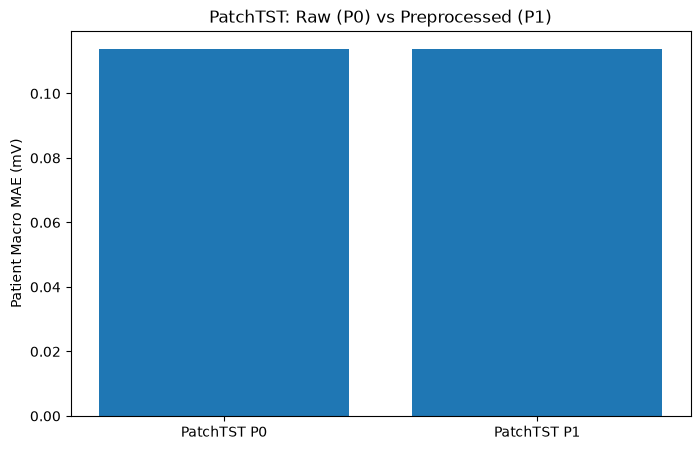

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.bar(
    comparison["Run"],
    comparison["Val MAE"]
)

plt.ylabel("Patient Macro MAE (mV)")
plt.title("PatchTST: Raw (P0) vs Preprocessed (P1)")

plt.tight_layout()

plt.savefig(
    FIG_DIR / "patchtst" / "patchtst_p0_vs_p1_mae.png",
    dpi=300,
    bbox_inches="tight"
)


(
    FIG_DIR
    / "patchtst"
    / "patchtst_p0_vs_p1.txt"
).write_text(caption)

plt.show()

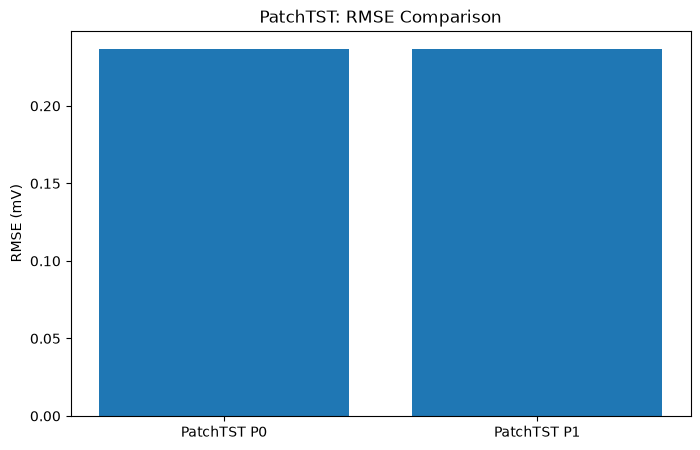

In [23]:
plt.figure(figsize=(8,5))

plt.bar(
    comparison["Run"],
    comparison["Val RMSE"]
)

plt.ylabel("RMSE (mV)")
plt.title("PatchTST: RMSE Comparison")

plt.show()

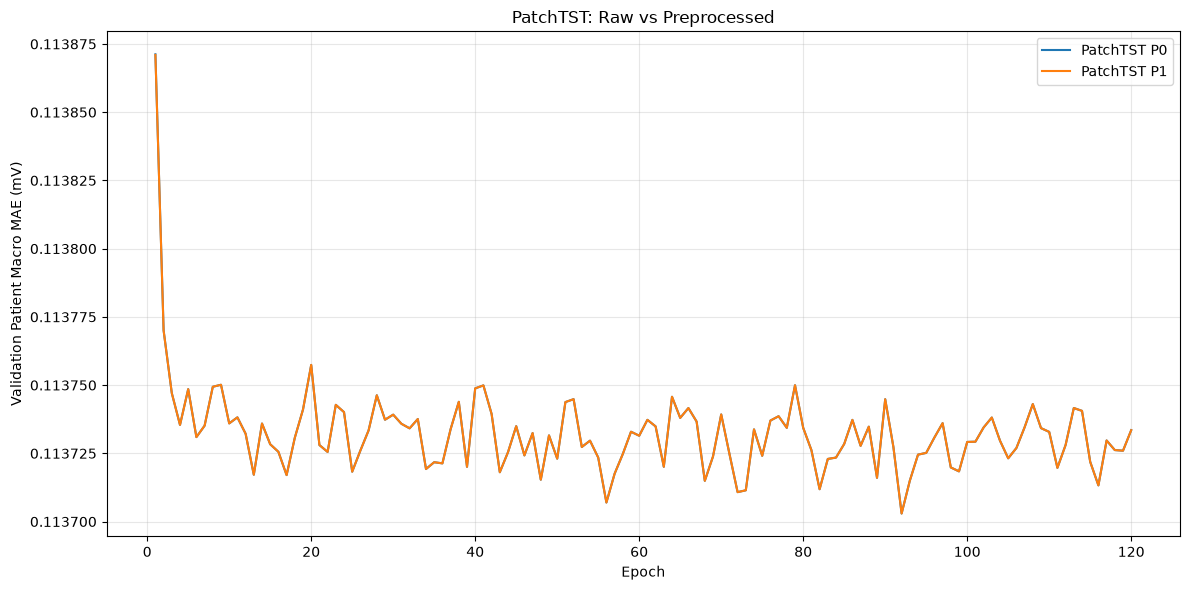

In [60]:
import pandas as pd

hist_p0 = pd.read_csv(
    "results/primary_7s3s_v3/full/checkpoints/patchtst_P0_F0_full_120e/history.csv"
)

hist_p1 = pd.read_csv(
    "results/primary_7s3s_v3/full/checkpoints/patchtst_P1_F0_full_120e/history.csv"
)

import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))

plt.plot(
    hist_p0["epoch"],
    hist_p0["val_patient_macro_mae_mV"],
    label="PatchTST P0"
)

plt.plot(
    hist_p1["epoch"],
    hist_p1["val_patient_macro_mae_mV"],
    label="PatchTST P1"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Patient Macro MAE (mV)")
plt.title("PatchTST: Raw vs Preprocessed")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    FIG_DIR / "patchtst" / "patchtst_p0_vs_p1_val_mae.png",
    dpi=300,
    bbox_inches="tight"
)


(
    FIG_DIR
    / "patchtst"
    / "patchtst_p0_vs_p1_val_mae.txt"
).write_text(caption)

plt.show()




In [16]:
from pathlib import Path

for run in [
    "patchtst_P0_F0_full_120e",
    "patchtst_P1_F0_full_120e",
    "tft_P0_F0_medium_60e",
]:
    p = (
        Path("results")
        / "primary_7s3s_v3"
        / ("full" if "patchtst" in run else "medium")
        / "checkpoints"
        / run
        / "history.csv"
    )

    print()
    print(run)
    print(p)
    print(p.exists())
    print(p.stat().st_size)


patchtst_P0_F0_full_120e
results/primary_7s3s_v3/full/checkpoints/patchtst_P0_F0_full_120e/history.csv
True
22319

patchtst_P1_F0_full_120e
results/primary_7s3s_v3/full/checkpoints/patchtst_P1_F0_full_120e/history.csv
True
22309

tft_P0_F0_medium_60e
results/primary_7s3s_v3/medium/checkpoints/tft_P0_F0_medium_60e/history.csv
True
11278


# Checking the difference between P0 and P1

In [17]:
import pandas as pd

p0 = pd.read_csv(
    "results/primary_7s3s_v3/full/checkpoints/patchtst_P0_F0_full_120e/history.csv"
)

p1 = pd.read_csv(
    "results/primary_7s3s_v3/full/checkpoints/patchtst_P1_F0_full_120e/history.csv"
)

print(
    (p0["val_patient_macro_mae_mV"] -
     p1["val_patient_macro_mae_mV"]).abs().max()
)

2.408349023957923e-07


In [22]:
from pathlib import Path
import numpy as np

from config import load_config
from data import prepare
from preprocessing import filtered_path

cfg = load_config(PROJECT_ROOT / "configs/config.yaml")

cfg["data"]["root"] = (
    "/media/ehsan/MyFiles2/FraUAS/HIS Project/PTB-XL"
)

cfg["run_mode"] = "full"

cache, manifest = prepare(cfg)

p0 = np.load(
    Path(cache) / "waves_train.npy",
    mmap_mode="r"
)

p1 = np.load(
    filtered_path(cache, cfg, "train"),
    mmap_mode="r"
)

difference = np.mean(
    np.abs(
        p0[0, : cfg["data"]["history"]] - p1[0]
    )
)

print("Mean absolute difference:", difference)

Mean absolute difference: 0.047097363


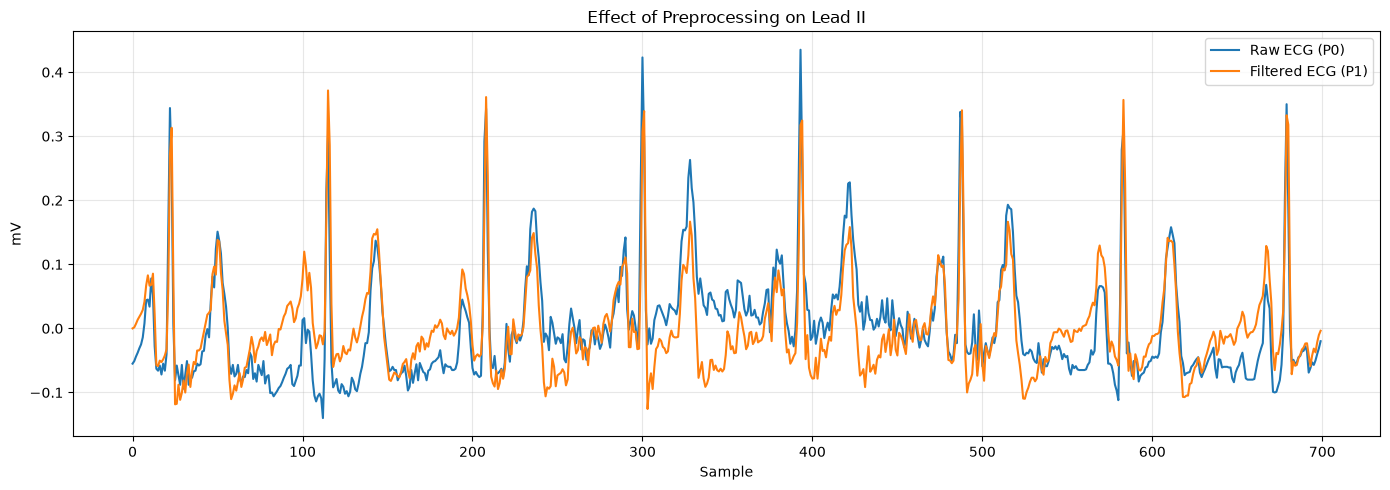

In [59]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

from preprocessing import filtered_path

cfg["run_mode"] = "full"
cache, manifest = prepare(cfg)

raw = np.load(
    Path(cache) / "waves_train.npy",
    mmap_mode="r"
)

filtered = np.load(
    filtered_path(cache, cfg, "train"),
    mmap_mode="r"
)

lead_names = [
    "I","II","III","aVR","aVL","aVF",
    "V1","V2","V3","V4","V5","V6"
]

lead = 1  # Lead II

plt.figure(figsize=(14,5))

plt.plot(
    raw[0,:700,lead],
    label="Raw ECG (P0)"
)

plt.plot(
    filtered[0,:,lead],
    label="Filtered ECG (P1)"
)

plt.title(
    f"Effect of Preprocessing on Lead {lead_names[lead]}"
)

plt.xlabel("Sample")
plt.ylabel("mV")

plt.legend()
plt.grid(alpha=0.3)


plt.tight_layout()

plt.savefig(
    FIG_DIR / "patchtst" / "patchtst_preprocessing_effect.png",
    dpi=300,
    bbox_inches="tight"
)


(
    FIG_DIR
    / "patchtst"
    / "patchtst_preprocessing_effect.txt"
).write_text(caption)

plt.show()


In [31]:
# Per Lead Performance

In [33]:
import torch
from pathlib import Path

from models import build_model
from data import ECGDataset
from preprocessing import feature_arrays

arrays, names, details = feature_arrays(
    cfg,
    cache,
    "F0",
    splits=("train", "val")
)

val_ds = ECGDataset(
    cache,
    cfg,
    "val",
    "P0",     # use P1 if you want the preprocessed model
    arrays["val"]
)

In [34]:
checkpoint = torch.load(
    "results/primary_7s3s_v3/full/checkpoints/patchtst_P0_F0_full_120e/best.pt",
    map_location="cpu",
    weights_only=False,
)

model = build_model(
    "patchtst",
    static_dim=0,
    horizon=cfg["data"]["horizon"],
    **cfg["model"]
)

model.load_state_dict(checkpoint["model"])
model.eval()

PatchTSTForecaster(
  (patch_embed): Linear(in_features=192, out_features=64, bias=True)
  (encoder): TransformerEncoder(
    (layers): ModuleList(
      (0): TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=64, out_features=64, bias=True)
        )
        (linear1): Linear(in_features=64, out_features=2048, bias=True)
        (dropout): Dropout(p=0.2, inplace=False)
        (linear2): Linear(in_features=2048, out_features=64, bias=True)
        (norm1): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
        (norm2): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
        (dropout1): Dropout(p=0.2, inplace=False)
        (dropout2): Dropout(p=0.2, inplace=False)
      )
    )
  )
  (head): Sequential(
    (0): Linear(in_features=5504, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=128, out_features=3600, bi

In [35]:
sample = val_ds[0]

history = sample["x"].unsqueeze(0)

with torch.inference_mode():
    prediction = model(history).squeeze(0)

prediction = prediction.numpy()
ground_truth = sample["y"].numpy()

print(prediction.shape)
print(ground_truth.shape)

(300, 12)
(300, 12)


In [36]:
import numpy as np
import pandas as pd

lead_names = [
    "I","II","III",
    "aVR","aVL","aVF",
    "V1","V2","V3",
    "V4","V5","V6"
]

lead_mae = np.mean(
    np.abs(
        prediction - ground_truth
    ),
    axis=0
)

pd.DataFrame({
    "Lead": lead_names,
    "MAE": lead_mae
}).sort_values("MAE")


,Lead,MAE
6,V1,0.371559
11,V6,0.424893
10,V5,0.503506
9,V4,0.592813
0,I,0.648992
8,V3,0.703391
7,V2,0.780413
3,aVR,0.885081
4,aVL,1.221444
1,II,1.532276


# Example validation ECG showing the 12-lead forecast produced by PatchTST compared with the ground-truth future waveform.

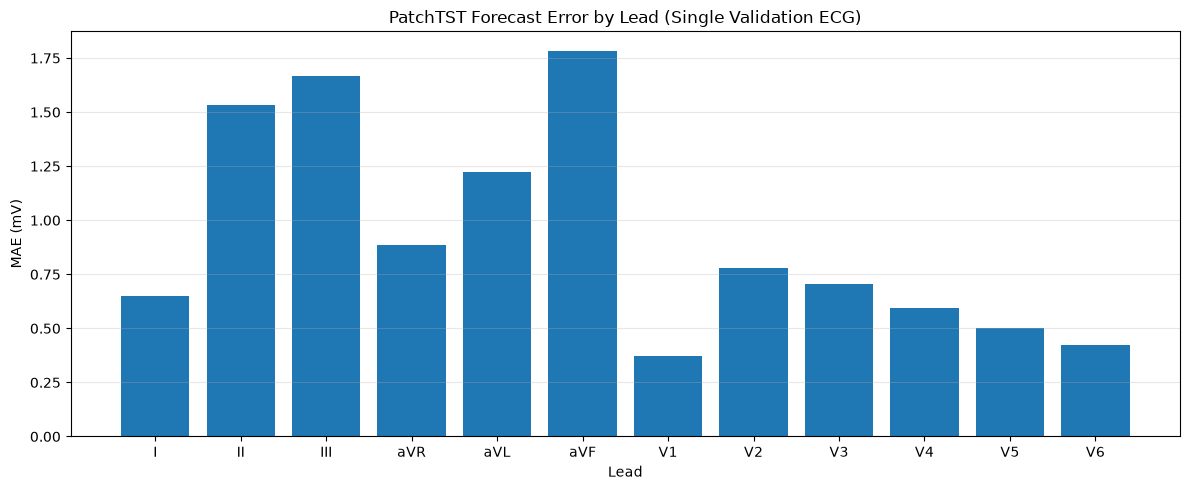

In [58]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))

plt.bar(
    lead_names,
    lead_mae
)

plt.ylabel("MAE (mV)")
plt.xlabel("Lead")

plt.title(
    "PatchTST Forecast Error by Lead (Single Validation ECG)"
)

plt.grid(axis="y", alpha=0.3)


plt.tight_layout()

plt.savefig(
    FIG_DIR / "patchtst" / "patchtst_per_lead_forecast_error.png",
    dpi=300,
    bbox_inches="tight"
)


(
    FIG_DIR
    / "patchtst"
    / "patchtst_per_lead_forecast_error.txt"
).write_text(caption)

plt.show()

# ==================================================
# FINAL RESULTS TABLE
# ==================================================

In [2]:
import pandas as pd

def best_metrics(history_file, model_name):
    df = pd.read_csv(history_file)

    best = df.loc[
        df["val_patient_macro_mae_mV"].idxmin()
    ]

    return {
        "Model": model_name,
        "Best Epoch": int(best["epoch"]),
        "MAE": best["val_patient_macro_mae_mV"],
        "RMSE": best["val_rmse_mV"],
        "MSE": best["val_mse_normalized"],
    }

# Summary Table for TFT and PatchTST

In [4]:
results = pd.DataFrame([
    best_metrics(
        "results/primary_7s3s_v3/full/checkpoints/patchtst_P0_F0_full_120e/history.csv",
        "PatchTST P0"
    ),
    best_metrics(
        "results/primary_7s3s_v3/full/checkpoints/patchtst_P1_F0_full_120e/history.csv",
        "PatchTST P1"
    ),
    best_metrics(
        "results/primary_7s3s_v3/medium/checkpoints/tft_P0_F0_medium_60e/history.csv",
        "TFT P0"
    ),
    best_metrics(
        "results/primary_7s3s_v3/medium/checkpoints/tft_P1_F0_medium_60e/history.csv",
        "TFT P1"
    )
])

results

,Model,Best Epoch,MAE,RMSE,MSE
0,PatchTST P0,92,0.113703,0.236500,0.990605
1,PatchTST P1,92,0.113703,0.236500,0.990605
2,TFT P0,31,0.108556,0.232228,1.011663
3,TFT P1,12,0.113963,0.236698,1.076473


# PatchTST vs TFT MAE

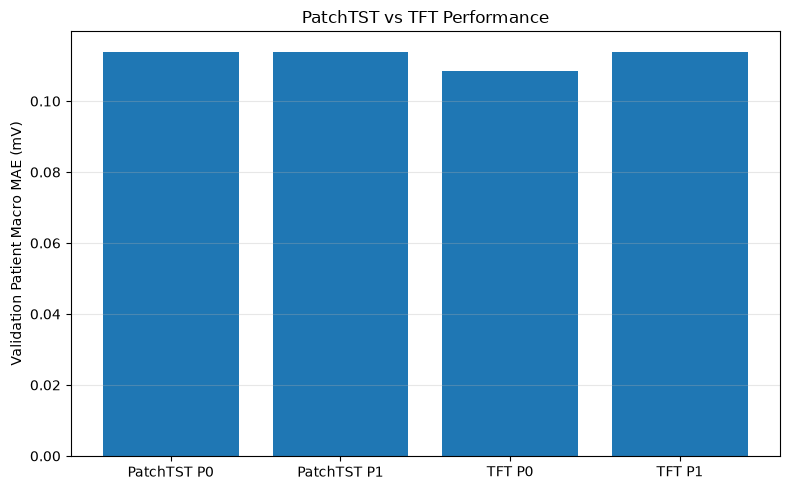

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.bar(
    results["Model"],
    results["MAE"]
)

plt.ylabel("Validation Patient Macro MAE (mV)")

plt.title(
    "PatchTST vs TFT Performance"
)

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    FIG_DIR / "comparison" / "transformer_mae_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# PatchTST vs TFT RMSE

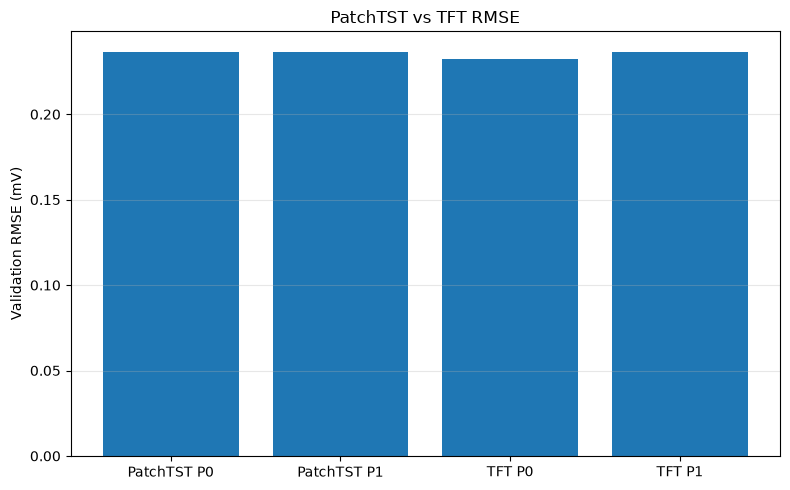

In [11]:
plt.figure(figsize=(8,5))

plt.bar(
    results["Model"],
    results["RMSE"]
)

plt.ylabel("Validation RMSE (mV)")

plt.title(
    "PatchTST vs TFT RMSE"
)

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    FIG_DIR / "comparison" / "transformer_rmse_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# TFT P0 vs TFT P1 Learning Curves

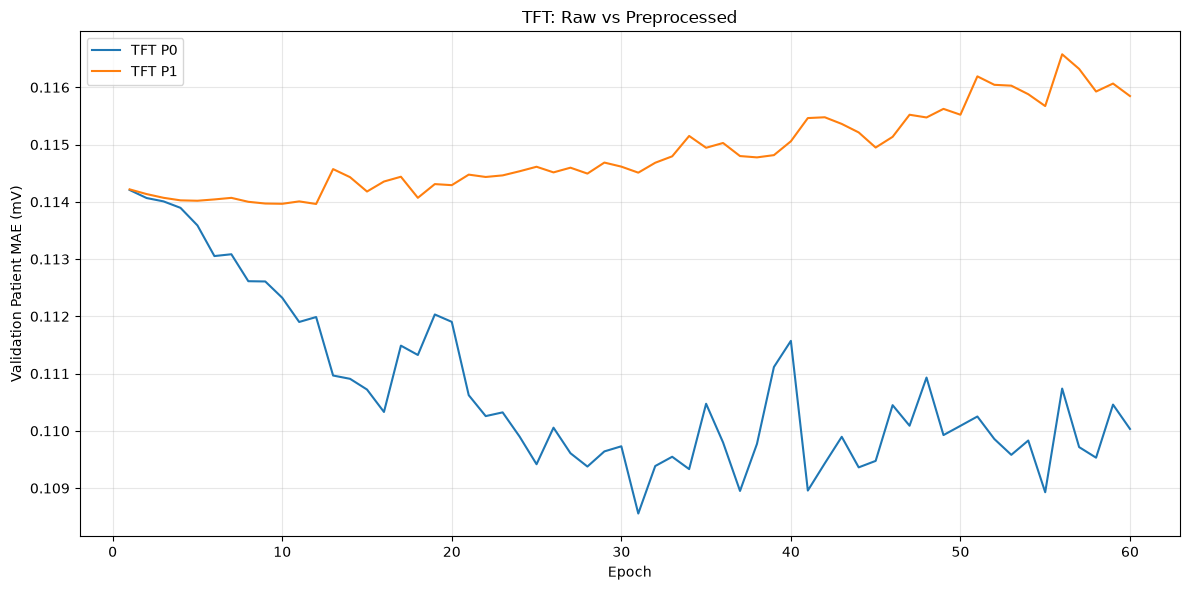

In [13]:
import pandas as pd
import matplotlib.pyplot as plt

tft_p0 = pd.read_csv(
    "results/primary_7s3s_v3/medium/checkpoints/tft_P0_F0_medium_60e/history.csv"
)

tft_p1 = pd.read_csv(
    "results/primary_7s3s_v3/medium/checkpoints/tft_P1_F0_medium_60e/history.csv"
)

plt.figure(figsize=(12,6))

plt.plot(
    tft_p0["epoch"],
    tft_p0["val_patient_macro_mae_mV"],
    label="TFT P0"
)

plt.plot(
    tft_p1["epoch"],
    tft_p1["val_patient_macro_mae_mV"],
    label="TFT P1"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Patient MAE (mV)")

plt.title("TFT: Raw vs Preprocessed")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    FIG_DIR / "tft" / "tft_p0_vs_p1_learning_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Learning Curves Comparison

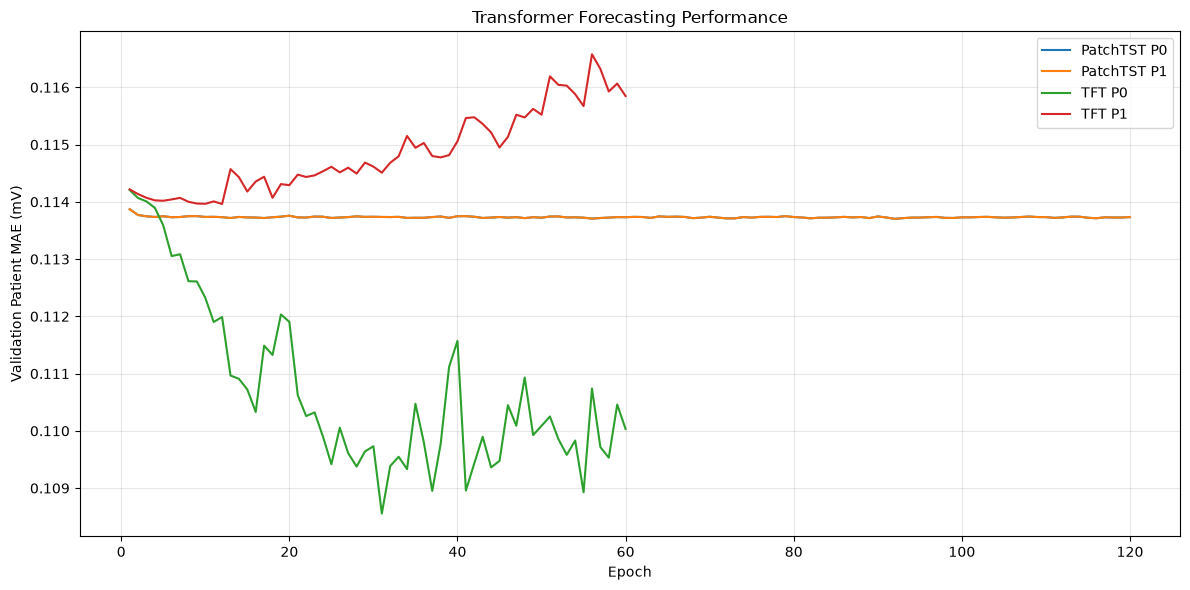

In [15]:
patch_p0 = pd.read_csv(
    "results/primary_7s3s_v3/full/checkpoints/patchtst_P0_F0_full_120e/history.csv"
)

patch_p1 = pd.read_csv(
    "results/primary_7s3s_v3/full/checkpoints/patchtst_P1_F0_full_120e/history.csv"
)

tft_p0 = pd.read_csv(
    "results/primary_7s3s_v3/medium/checkpoints/tft_P0_F0_medium_60e/history.csv"
)

tft_p1 = pd.read_csv(
    "results/primary_7s3s_v3/medium/checkpoints/tft_P1_F0_medium_60e/history.csv"
)

plt.figure(figsize=(12,6))

plt.plot(
    patch_p0["epoch"],
    patch_p0["val_patient_macro_mae_mV"],
    label="PatchTST P0"
)

plt.plot(
    patch_p1["epoch"],
    patch_p1["val_patient_macro_mae_mV"],
    label="PatchTST P1"
)

plt.plot(
    tft_p0["epoch"],
    tft_p0["val_patient_macro_mae_mV"],
    label="TFT P0"
)

plt.plot(
    tft_p1["epoch"],
    tft_p1["val_patient_macro_mae_mV"],
    label="TFT P1"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Patient MAE (mV)")

plt.title(
    "Transformer Forecasting Performance"
)

plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()

plt.savefig(
    FIG_DIR / "comparison" / "all_transformers_learning_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [16]:
results

,Model,Best Epoch,MAE,RMSE,MSE
0,PatchTST P0,92,0.113703,0.236500,0.990605
1,PatchTST P1,92,0.113703,0.236500,0.990605
2,TFT P0,31,0.108556,0.232228,1.011663
3,TFT P1,12,0.113963,0.236698,1.076473


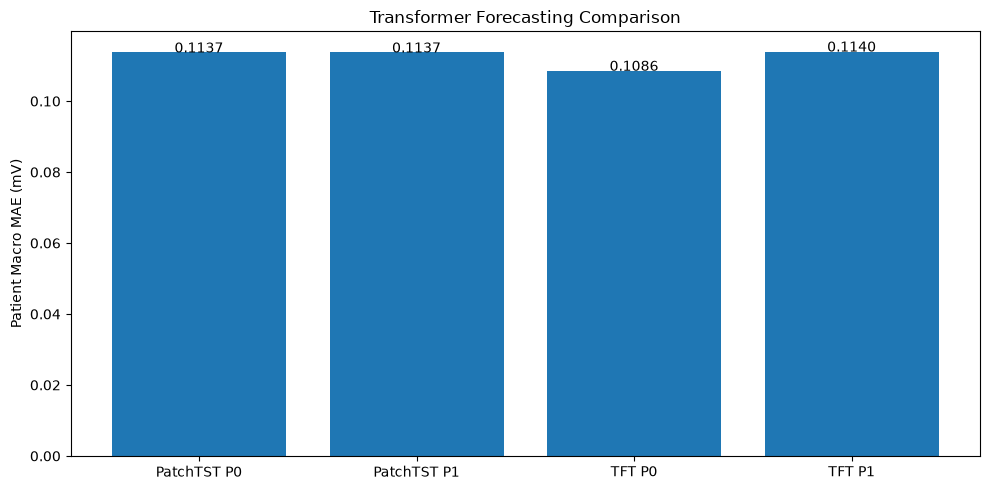

In [17]:
import matplotlib.pyplot as plt

models = [
    "PatchTST P0",
    "PatchTST P1",
    "TFT P0",
    "TFT P1"
]

mae = [
    0.113703,
    0.113703,
    0.108556,
    0.113963
]

plt.figure(figsize=(10,5))

bars = plt.bar(
    models,
    mae
)

plt.ylabel("Patient Macro MAE (mV)")
plt.title("Transformer Forecasting Comparison")

for b in bars:
    plt.text(
        b.get_x()+b.get_width()/2,
        b.get_height(),
        f"{b.get_height():.4f}",
        ha="center"
    )

plt.tight_layout()

plt.savefig(
    FIG_DIR / "comparison" / "transformer_mae_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ==================================================
# PER-LEAD PERFORMANCE ANALYSIS
# ==================================================

In [19]:
#Loading best PatchTST model
import torch
from pathlib import Path

from models import build_model

checkpoint = torch.load(
    "results/primary_7s3s_v3/full/checkpoints/patchtst_P0_F0_full_120e/best.pt",
    map_location="cpu",
    weights_only=False,
)

patchtst = build_model(
    "patchtst",
    static_dim=0,
    horizon=cfg["data"]["horizon"],
    **cfg["model"]
)

patchtst.load_state_dict(checkpoint["model"])
patchtst.eval()


PatchTSTForecaster(
  (patch_embed): Linear(in_features=192, out_features=64, bias=True)
  (encoder): TransformerEncoder(
    (layers): ModuleList(
      (0): TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=64, out_features=64, bias=True)
        )
        (linear1): Linear(in_features=64, out_features=2048, bias=True)
        (dropout): Dropout(p=0.2, inplace=False)
        (linear2): Linear(in_features=2048, out_features=64, bias=True)
        (norm1): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
        (norm2): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
        (dropout1): Dropout(p=0.2, inplace=False)
        (dropout2): Dropout(p=0.2, inplace=False)
      )
    )
  )
  (head): Sequential(
    (0): Linear(in_features=5504, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=128, out_features=3600, bi

In [24]:
# Loading Validation data for P0

from data import ECGDataset
from preprocessing import feature_arrays

arrays, names, details = feature_arrays(
    cfg,
    cache,
    "F0",
    splits=("train", "val")
)

val_ds = ECGDataset(
    cache,
    cfg,
    "val",
    "P0",
    arrays["val"]
)

In [25]:
#Loading best PatchTST model for P1
import torch
from pathlib import Path

from models import build_model

checkpoint = torch.load(
    "results/primary_7s3s_v3/full/checkpoints/patchtst_P1_F0_full_120e/best.pt",
    map_location="cpu",
    weights_only=False,
)

patchtst = build_model(
    "patchtst",
    static_dim=0,
    horizon=cfg["data"]["horizon"],
    **cfg["model"]
)

patchtst.load_state_dict(checkpoint["model"])
patchtst.eval()

# Loading Validation data for P1

from data import ECGDataset
from preprocessing import feature_arrays

arrays, names, details = feature_arrays(
    cfg,
    cache,
    "F0",
    splits=("train", "val")
)

val_ds = ECGDataset(
    cache,
    cfg,
    "val",
    "P1",
    arrays["val"]
)

In [26]:
import numpy as np

lead_errors = []

with torch.inference_mode():

    for sample_idx in range(len(val_ds)):

        sample = val_ds[sample_idx]

        history = sample["x"].unsqueeze(0)

        prediction = patchtst(history).squeeze(0).numpy()

        target = sample["y"].numpy()

        lead_mae = np.mean(
            np.abs(
                prediction - target
            ),
            axis=0
        )

        lead_errors.append(lead_mae)

lead_errors = np.asarray(lead_errors)

mean_lead_mae = lead_errors.mean(axis=0)

mean_lead_mae

array([0.5252514 , 0.6073772 , 0.5175762 , 0.5703411 , 0.5002893 ,
       0.5707194 , 0.50331   , 0.50531477, 0.54429215, 0.5756148 ,
       0.5915807 , 0.51687   ], dtype=float32)

In [27]:
import pandas as pd

lead_names = [
    "I","II","III",
    "aVR","aVL","aVF",
    "V1","V2","V3",
    "V4","V5","V6"
]

patchtst_leads = pd.DataFrame({
    "Lead": lead_names,
    "MAE": mean_lead_mae
})

patchtst_leads

,Lead,MAE
0,I,0.525251
1,II,0.607377
2,III,0.517576
3,aVR,0.570341
4,aVL,0.500289
5,aVF,0.570719
6,V1,0.503310
7,V2,0.505315
8,V3,0.544292
9,V4,0.575615


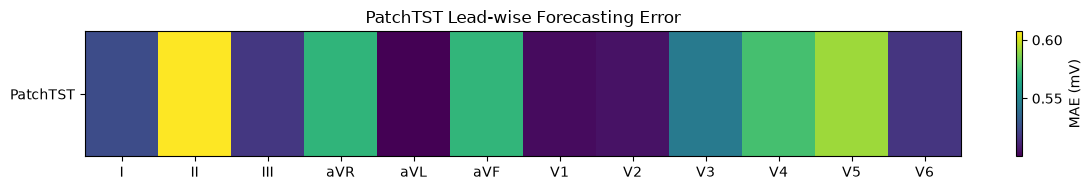

In [28]:
plt.figure(figsize=(12,2))

plt.imshow(
    mean_lead_mae.reshape(1,-1),
    aspect="auto",
    cmap="viridis"
)

plt.xticks(
    np.arange(len(lead_names)),
    lead_names
)

plt.yticks([0], ["PatchTST"])

plt.colorbar(label="MAE (mV)")

plt.title(
    "PatchTST Lead-wise Forecasting Error"
)

plt.tight_layout()

plt.savefig(
    FIG_DIR / "leads" / "patchtst_p0_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()